# Vagalume — rota mais segura com programação dinâmica

**Global Solution FIAP 2026.2 · CitizenTech · Dynamic Programming**

O Vagalume sugere a rota mais segura de um ponto A a um ponto B e, se a pessoa se sentir em risco no caminho, indica o Ponto Seguro aberto mais próximo. Este notebook resolve a parte algorítmica: **qual é a rota de menor risco que anda no máximo _B_ metros a mais que a mais curta?**

| | |
|---|---|
| Cidade e bairro | São Paulo, Paulista e Bela Vista (piloto) |
| Cidadão beneficiado | Quem se desloca a pé, com foco em mulheres, LGBTQIA+, idosos e quem volta tarde |
| ODS | 3 (3.4, 3.5, 3.6), 10 e 11 (11.2, 11.7) |

**Integração com as outras disciplinas:** a densidade de risco de cada trecho usa as ocorrências tratadas em *Data Science*; os nós, trechos e pontos seguem as entidades `TRECHO`, `REPORT`, `OCORRENCIA_OFICIAL` e `PONTO_APOIO` de *Database Design*; a mesma lógica é a classe `RoteirizadorService` em *Java*; e a API que roda este algoritmo fica no servidor do Ponto Seguro montado em *Network*.

## 1. Problema

Muitas pessoas, principalmente mulheres, escolhem a rota pelo tempo e não pela segurança, porque não sabem quais trechos são mais arriscados. O app deixa a pessoa dizer **quanto aceita andar a mais** (o controle deslizante de desvio) e devolve a rota de **menor exposição ao risco** que cabe nesse orçamento.

- **Entrada:** grafo de ruas, origem, destino, orçamento de desvio *B* (metros) e horário.
- **Saída:** a rota (sequência de esquinas), a distância, o desvio usado, a nota de segurança de 0 a 100 e os motivos da nota.

O Dijkstra puro só minimiza **uma** grandeza e é guloso. Aqui há **duas** (distância e risco) com uma restrição, o que é um *caminho mínimo com restrição de recurso*: um problema clássico de programação dinâmica.

## 2. Fonte dos dados

O recorte é a região da Av. Paulista e da Bela Vista: 5 ruas paralelas × 5 transversais, com 25 esquinas e 40 trechos. Os combinados da GS proíbem dados pessoais reais, então tudo o que é sensível é simulado, e isso está declarado abaixo.

| Arquivo / coluna | Origem | Situação |
|---|---|---|
| `nos.csv`: nomes das ruas e esquinas | [OpenStreetMap](https://www.openstreetmap.org) (traçado real, simplificado em grade) | Real, simplificado; coordenadas aproximadas em metros |
| `arestas.csv` → `comprimento_m` | Medido no OpenStreetMap, arredondado | Aproximado |
| `arestas.csv` → `ocorrencias` | Formato das ocorrências da [SSP-SP](https://www.ssp.sp.gov.br/estatistica/consultas) (registros/ano por trecho) | **Simulado** no formato da SSP; na versão integrada vem do CSV de Data Science |
| `arestas.csv` → `iluminacao` | Dados abertos da Prefeitura de SP (iluminação pública) | **Simulado** (0 = escuro, 1 = bem iluminado) |
| `arestas.csv` → `movimento` | Comércios abertos à noite no OpenStreetMap | **Simulado** (0 = deserto, 1 = muito movimento) |
| `arestas.csv` → `reports` | Reports da comunidade no app | **Simulado** (últimos 30 dias) |
| `arestas.csv` → `acidentes` | CET / DETRAN-SP (meta ODS 3.6) | **Simulado** |
| `pontos_seguros.csv` | Rede de Pontos Seguros (comércios parceiros e órgãos públicos) | **Simulado**, 10 pontos |

In [1]:
import time
import inspect
import pandas as pd
import matplotlib.pyplot as plt
import rota_dp as rd

grafo = rd.carregar_grafo()
pontos = rd.carregar_pontos_seguros()
arestas = pd.read_csv("dados/arestas.csv")
print(f"{len(grafo.nos)} esquinas, {len(arestas)} trechos, {len(pontos)} Pontos Seguros")
arestas.head(8)

25 esquinas, 40 trechos, 10 Pontos Seguros


,origem,destino,rua,comprimento_m,ocorrencias,iluminacao,movimento,reports,acidentes
0,P1,P2,Av. Paulista,230,7,0.95,0.90,1,2
1,P2,P3,Av. Paulista,180,6,0.95,0.90,1,2
2,P3,P4,Av. Paulista,200,6,0.95,0.85,1,1
3,P4,P5,Av. Paulista,190,5,0.95,0.85,0,2
4,C1,C2,R. São Carlos do Pinhal,230,4,0.60,0.45,2,1
5,C2,C3,R. São Carlos do Pinhal,180,4,0.55,0.40,2,0
6,C3,C4,R. São Carlos do Pinhal,200,5,0.60,0.35,3,1
7,C4,C5,R. São Carlos do Pinhal,190,3,0.65,0.40,1,0


## 3. Modelagem

**Estrutura de dados: grafo em lista de adjacência.** As esquinas são nós e os trechos de rua são arestas, nos dois sentidos (a pé, não há contramão). A lista de adjacência (`grafo.adj[u]` = trechos que saem de `u`) ocupa O(V + E) e percorre só os vizinhos reais. Uma matriz de adjacência gastaria O(V²) com uma malha viária esparsa, em que cada esquina tem 2 a 4 vizinhos.

Cada aresta guarda dois pesos:
- **distância**, discretizada em passos de 10 m (arredondada para cima, no mínimo 1 passo);
- **risco = comprimento × densidade de risco**. O risco é a *exposição*: andar 300 m numa rua escura pesa mais que andar 30 m nela.

**Tabela da DP: `dp[v][d]`**, uma matriz V × (D + 1), com `D = passos mínimos + B / passo`. Ela guarda o menor risco para chegar ao nó `v` andando exatamente `d` passos. Uma segunda matriz `pai[v][d]` guarda de onde veio cada valor, para reconstruir a rota.

### Motor de risco

A densidade de risco (risco por metro) de um trecho no horário *h* combina os fatores do Vagalume:

$$\text{dens} = \big(0{,}05 + 0{,}40\,\tfrac{\text{ocorr}}{10}\,p_h + 0{,}30\,(1-\text{ilum})\,q_h + 0{,}25\,\tfrac{\text{reports}}{8}\,r_h + 0{,}10\,\tfrac{\text{acid}}{5}\big)\times(1 - 0{,}5\,\text{movimento})$$

Os pesos *p_h*, *q_h* e *r_h* valem 1 à noite (19h às 6h) e são menores de dia, quando a iluminação quase não importa. Toda densidade tem um mínimo de 0,02, então **todo trecho tem risco > 0**. Essa garantia é usada na prova de correção.

In [2]:
tabela = pd.DataFrame([{"trecho": f"{t.origem}–{t.destino}", "rua": t.rua, "m": t.comprimento_m,
                        "dens. 15h": round(rd.densidade_risco(t, 15), 3),
                        "dens. 23h": round(rd.densidade_risco(t, 23), 3)}
                       for t in grafo.trechos() if t.origem < t.destino])
tabela.groupby("rua")[["dens. 15h", "dens. 23h"]].mean().round(3).sort_values("dens. 23h", ascending=False)

,dens. 15h,dens. 23h
rua,,
R. Cincinato Braga,0.248,0.606
R. São Carlos do Pinhal,0.170,0.322
R. Pamplona,0.161,0.294
Al. Campinas,0.138,0.291
Al. Casa Branca,0.128,0.277
R. Augusta,0.175,0.242
Al. Jaú,0.115,0.219
Av. Paulista,0.164,0.204
Al. Joaquim Eugênio de Lima,0.108,0.182


## 4. Algoritmo

**Recorrência**

$$dp[v][0] = \begin{cases}0 & v = \text{origem}\\ \infty & \text{caso contrário}\end{cases}\qquad dp[v][d] = \min_{(u \to v)} \; dp[u][d - w_{uv}] + r_{uv}$$

$$\text{resposta} = \min_{d \,\le\, D} dp[\text{destino}][d]$$

**Por que está correto**
1. Todo trecho tem pelo menos 1 passo, então `dp[v][d]` só depende de valores com `d` menor. Preenchendo a tabela em ordem crescente de `d`, cada valor usado já está pronto, e não há dependência circular.
2. Todo trecho tem risco > 0. Um caminho que passa duas vezes pela mesma esquina pode perder o ciclo e fica mais curto e menos arriscado, ainda dentro do orçamento. Logo, a solução ótima da DP é sempre um caminho simples, igual ao da força bruta (o teste `test_dp_igual_forca_bruta_em_grafos_aleatorios` confirma isso em 30 grafos).
3. Com orçamento 0, `D` é a distância mínima, e a DP devolve **a menos arriscada entre as rotas mais curtas**.

O passo 1 do código usa um Dijkstra só para descobrir a distância mínima e dimensionar a tabela. A escolha da rota é toda feita pela DP.

**O código, com cada etapa comentada:**

In [3]:
print(inspect.getsource(rd.rota_mais_segura))

def rota_mais_segura(grafo: Grafo, origem: str, destino: str, orcamento_m: float,
                     hora: int = 23, passo_m: int = 10) -> Resultado | None:
    """Rota de menor risco que anda no máximo `orcamento_m` metros a mais que a mais curta.

    Retorna None se o destino for inalcançável.
    Tempo O(E · D) e memória O(V · D), com D = passos_minimos + orcamento_m / passo_m.
    """
    _validar(grafo, origem, destino, orcamento_m, passo_m)
    if origem == destino:
        return Resultado([origem], [], 0.0, 0, 0, passo_m, hora)

    # 1) Tamanho da tabela: distância mínima + orçamento, em passos.
    passos_minimos = menor_distancia_passos(grafo, origem, passo_m).get(destino)
    if passos_minimos is None:
        return None
    D = passos_minimos + int(orcamento_m // passo_m)

    # 2) Pré-calcula, para cada trecho u -> v: (u, v, passos, risco, trecho).
    indice = {v: i for i, v in enumerate(grafo.adj)}
    arestas = [(indice[t.origem], indice[t.destino], passos(t, passo

## 5. Exemplos de entrada e saída

**Cenário:** às 23h, a pessoa sai da R. Cincinato Braga × R. Augusta (`B1`) e vai até a R. Cincinato Braga × Al. Joaquim Eugênio de Lima (`B5`). O caminho mais curto segue reto pela Cincinato Braga, que é escura e tem muitos reports de assédio. Vejamos o que acontece com orçamentos de 0, 200 e 500 m.

In [4]:
def resumo(r, rotulo):
    return {"cenário": rotulo, "distância (m)": r.distancia_m, "desvio (m)": r.desvio_m,
            "+ minutos a pé": round(r.desvio_m / 80, 1), "risco": round(r.risco, 1),
            "nota 0–100": r.nota_seguranca, "m de alto risco": r.metros_alto_risco,
            "ruas": " → ".join(r.ruas)}

rotas = {b: rd.rota_mais_segura(grafo, "B1", "B5", orcamento_m=b, hora=23) for b in (0, 200, 500)}
pd.DataFrame([resumo(r, f"B = {b} m, 23h") for b, r in rotas.items()])

,cenário,distância (m),desvio (m),+ minutos a pé,risco,nota 0–100,m de alto risco,ruas
0,"B = 0 m, 23h",800.0,0,0.0,484.2,39,800.0,R. Cincinato Braga
1,"B = 200 m, 23h",1000.0,200,2.5,302.5,70,0.0,R. Augusta → R. São Carlos do Pinhal → Al. Joa...
2,"B = 500 m, 23h",1280.0,480,6.0,270.3,79,0.0,R. Augusta → Av. Paulista → Al. Joaquim Eugêni...


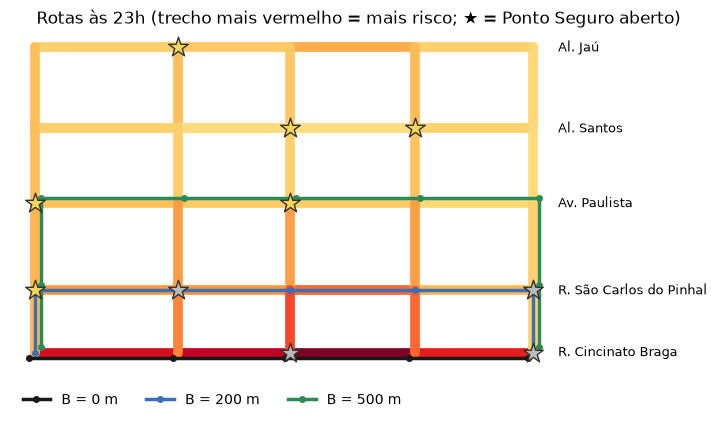

In [5]:
def desenhar(rotas_rotuladas, hora, titulo):
    fig, ax = plt.subplots(figsize=(9, 6))
    cmap = plt.get_cmap("YlOrRd")
    for t in grafo.trechos():
        if t.origem < t.destino:
            a, b = grafo.nos[t.origem], grafo.nos[t.destino]
            ax.plot([a["x"], b["x"]], [a["y"], b["y"]], color=cmap(rd.densidade_risco(t, hora) / 0.7),
                    lw=7, solid_capstyle="round", zorder=1)
    cores = ["#181818", "#3B6FB6", "#2E8B57"]
    for k, (rotulo, r) in enumerate(rotas_rotuladas):
        desloc = (k - 1) * 9
        xs = [grafo.nos[v]["x"] + desloc for v in r.caminho]
        ys = [grafo.nos[v]["y"] + desloc for v in r.caminho]
        ax.plot(xs, ys, color=cores[k], lw=2.5, marker="o", ms=4, label=rotulo, zorder=3)
    for p in pontos:
        n = grafo.nos[p["no"]]
        aberto = rd.esta_aberto(p, hora)
        ax.scatter(n["x"], n["y"], marker="*", s=220, zorder=4,
                   color="#F9D657" if aberto else "#BBBBBB", edgecolor="#323232")
    for nome, y in [("Al. Jaú", 490), ("Al. Santos", 360), ("Av. Paulista", 240),
                    ("R. São Carlos do Pinhal", 100), ("R. Cincinato Braga", 0)]:
        ax.text(840, y, nome, va="center", fontsize=9)
    ax.set_xlim(-40, 1080); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(titulo); ax.legend(loc="upper left", bbox_to_anchor=(0, -0.02), ncol=3, frameon=False)
    plt.show()

desenhar([(f"B = {b} m", r) for b, r in rotas.items()], 23,
         "Rotas às 23h (trecho mais vermelho = mais risco; ★ = Ponto Seguro aberto)")

**Explicabilidade:** o app lista, em linguagem simples, os fatores que mais pesaram na nota.

In [6]:
for b, r in rotas.items():
    print(f"B = {b} m  →  nota {r.nota_seguranca}")
    for frase in rd.explicar_rota(r):
        print("   •", frase)

B = 0 m  →  nota 39
   • Iluminação ruim: 34% do risco (pior trecho: R. Cincinato Braga, 200 m)
   • Ocorrências registradas: 33% do risco (pior trecho: R. Cincinato Braga, 200 m)
   • Reports recentes da comunidade: 31% do risco (pior trecho: R. Cincinato Braga, 200 m)
   • Movimento e comércios abertos reduziram o risco em 7%
B = 200 m  →  nota 70
   • Ocorrências registradas: 46% do risco (pior trecho: R. São Carlos do Pinhal, 200 m)
   • Iluminação ruim: 32% do risco (pior trecho: R. São Carlos do Pinhal, 230 m)
   • Reports recentes da comunidade: 18% do risco (pior trecho: R. São Carlos do Pinhal, 200 m)
   • Movimento e comércios abertos reduziram o risco em 22%
B = 500 m  →  nota 79
   • Ocorrências registradas: 68% do risco (pior trecho: Av. Paulista, 230 m)
   • Acidentes de trânsito: 11% do risco (pior trecho: Av. Paulista, 230 m)
   • Iluminação ruim: 11% do risco (pior trecho: Al. Joaquim Eugênio de Lima, 140 m)
   • Movimento e comércios abertos reduziram o risco em 41%


### O horário muda a rota

A mesma rua pode ser segura às 15h e arriscada às 23h. Com o mesmo orçamento de 500 m, à tarde não vale a pena subir até a Paulista: a R. São Carlos do Pinhal já basta.

In [7]:
dia = rd.rota_mais_segura(grafo, "B1", "B5", 500, hora=15)
noite = rotas[500]
pd.DataFrame([resumo(dia, "B = 500 m, 15h"), resumo(noite, "B = 500 m, 23h")])

,cenário,distância (m),desvio (m),+ minutos a pé,risco,nota 0–100,m de alto risco,ruas
0,"B = 500 m, 15h",1000.0,200,2.5,166.1,83,0,R. Augusta → R. São Carlos do Pinhal → Al. Joa...
1,"B = 500 m, 23h",1280.0,480,6.0,270.3,79,0,R. Augusta → Av. Paulista → Al. Joaquim Eugêni...


### Extensão: Ponto Seguro mais próximo

Quando a pessoa toca em "Me sinto insegura", o app calcula a distância a pé até todos os pontos com **Bellman-Ford**, que também é uma programação dinâmica: `dist_k[v]` = menor distância usando até *k* trechos. O algoritmo indica o ponto **aberto** mais próximo e, se houver um órgão público a até 150 m a mais, mostra-o na frente. Um ponto fechado nunca é sugerido.

In [8]:
for atual, hora in [("B3", 23), ("B3", 12), ("C1", 23)]:
    print(f"Em {grafo.nos[atual]['nome']}, às {hora}h:")
    for p in rd.ponto_seguro_mais_proximo(grafo, atual, hora, pontos):
        print(f"   → {p['nome']} ({p['tipo']}), {p['distancia_m']:.0f} m: {' → '.join(p['caminho'])}")
print("Em qualquer caso, o app mostra 190 (polícia) e 180 (Central de Atendimento à Mulher) em destaque.")

Em R. Cincinato Braga × Al. Campinas, às 23h:
   → Farmácia 24h Paulista (simulada) (comercio), 240 m: B3 → C3 → P3
Em R. Cincinato Braga × Al. Campinas, às 12h:
   → Mercado Cincinato (simulado) (comercio), 0 m: B3
Em R. São Carlos do Pinhal × R. Augusta, às 23h:
   → Base Comunitária da PM (simulada) (orgao_publico), 140 m: C1 → P1
   → Posto de combustível Augusta (simulado) (comercio), 0 m: C1
Em qualquer caso, o app mostra 190 (polícia) e 180 (Central de Atendimento à Mulher) em destaque.


## 6. Testes

Os testes de `test_rota_dp.py` cobrem:
- **as bordas:** orçamento zero, destino inalcançável, origem igual ao destino e entradas inválidas;
- **o cenário:** a rota muda com o orçamento e com o horário, e evita trechos de alto risco;
- **a correção:** DP igual à força bruta em 30 grafos aleatórios; o risco nunca aumenta com mais orçamento; a rota é válida e respeita o orçamento;
- **os Pontos Seguros:** nunca sugere ponto fechado, entende horário de madrugada e dá prioridade ao órgão público.

In [9]:
import sys, unittest, test_rota_dp
resultado = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromModule(test_rota_dp))
print("TODOS OS TESTES PASSARAM" if resultado.wasSuccessful() else "HÁ FALHAS")

test_destino_inalcancavel (test_rota_dp.TestBordas.test_destino_inalcancavel) ... 

ok


test_entradas_invalidas (test_rota_dp.TestBordas.test_entradas_invalidas) ... 

ok


test_orcamento_zero_retorna_rota_mais_curta (test_rota_dp.TestBordas.test_orcamento_zero_retorna_rota_mais_curta) ... 

ok


... (18 outputs left out)

test_orgao_publico_proximo_aparece_primeiro (test_rota_dp.TestPontoSeguro.test_orgao_publico_proximo_aparece_primeiro) ... 

ok


----------------------------------------------------------------------
Ran 13 tests in 0.060s

OK


TODOS OS TESTES PASSARAM


## 7. Eficiência

| | Tempo | Memória |
|---|---|---|
| Pré-processamento (Dijkstra para a distância mínima) | O(E log V) | O(V) |
| **DP `rota_mais_segura`** | **O(E · D)** | **O(V · D)** |
| Bellman-Ford (Ponto Seguro) | O(V · E) | O(V) |
| Força bruta (todos os caminhos simples) | exponencial | O(V) |

`D = (distância mínima + B) / passo` é o número de colunas da tabela. No cenário da Paulista, com E = 80 trechos direcionados e D = 130 passos, são cerca de 10 mil operações. O passo de 10 m equilibra precisão e custo: 5 m dobraria `D`, e 50 m perderia trechos curtos.

Abaixo, a DP e a força bruta resolvem o mesmo problema em grades cada vez maiores (orçamento de 1000 m; a força bruta só vai até 7×7 porque depois leva minutos).

In [10]:
medicoes = []
for n in range(3, 11):
    g = rd.gerar_grade(n, semente=n)
    o, d = "0,0", f"{n-1},{n-1}"
    t0 = time.perf_counter(); r = rd.rota_mais_segura(g, o, d, 1000); t_dp = time.perf_counter() - t0
    linha = {"grade": f"{n}×{n}", "esquinas (V)": n * n, "trechos (E)": 4 * n * (n - 1),
             "colunas (D)": r.passos_minimos + 100, "DP (ms)": round(1000 * t_dp, 2)}
    if n <= 7:
        t0 = time.perf_counter(); fb = rd.forca_bruta(g, o, d, 1000); t_fb = time.perf_counter() - t0
        assert abs(fb[0] - r.risco) < 1e-6
        linha.update({"força bruta (ms)": round(1000 * t_fb, 2), "caminhos explorados": fb[2]})
    medicoes.append(linha)
medicoes = pd.DataFrame(medicoes)
medicoes

,grade,esquinas (V),trechos (E),colunas (D),DP (ms),força bruta (ms),caminhos explorados
0,3×3,9,24,158,0.35,0.09,51.0
1,4×4,16,48,161,0.63,1.55,1074.0
2,5×5,25,80,216,1.52,34.42,22960.0
3,6×6,36,120,211,2.28,216.15,137099.0
4,7×7,49,168,249,4.52,2501.17,1500392.0
5,8×8,64,224,250,5.02,NaN,NaN
6,9×9,81,288,295,7.50,NaN,NaN
7,10×10,100,360,315,9.82,NaN,NaN


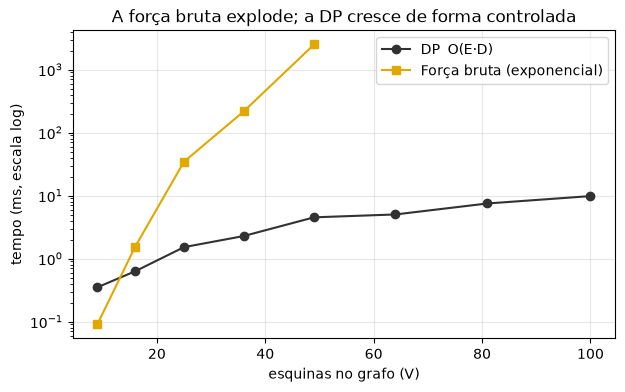

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(medicoes["esquinas (V)"], medicoes["DP (ms)"], marker="o", label="DP  O(E·D)", color="#323232")
ax.plot(medicoes["esquinas (V)"], medicoes["força bruta (ms)"], marker="s", label="Força bruta (exponencial)",
        color="#E0A800")
ax.set_yscale("log"); ax.set_xlabel("esquinas no grafo (V)"); ax.set_ylabel("tempo (ms, escala log)")
ax.set_title("A força bruta explode; a DP cresce de forma controlada"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## 8. Conclusões

- **Com 200 m a mais (cerca de 2,5 min a pé)**, a rota sai da R. Cincinato Braga, deixa de passar por 800 m de trecho de alto risco e cai de 484 para 303 unidades de risco. **Com 500 m (cerca de 6 min)**, chega à Paulista, iluminada e movimentada, e a nota sobe de 39 para 79.
- O horário importa: à tarde, a mesma pessoa não precisa do desvio inteiro.
- A DP garante a rota **ótima** dentro do orçamento, que é exatamente o controle que o app oferece ao usuário, com custo O(E · D). A força bruta, que daria o mesmo resultado, fica inviável já em grades pequenas.
- **Indicadores de impacto calculados aqui:** metros de trecho de alto risco evitados (`metros_alto_risco` da rota rápida menos o da segura) e tempo extra aceito (`desvio_m`).
- **Próximos passos:** trocar os dados simulados pelo CSV da SSP tratado em Data Science, ler a malha completa do OpenStreetMap e recalcular as densidades a cada novo report confirmado.